In [1]:
medical_charges_url = 'https://raw.githubusercontent.com/JovianML/opendatasets/master/data/medical-charges.csv'

In [2]:
from urllib.request import urlretrieve # for download data from dataset

In [3]:
urlretrieve(medical_charges_url, 'medical.csv') # this function download data in file name medical.csv

('medical.csv', <http.client.HTTPMessage at 0x1fc3c526990>)

In [4]:
!pip install pandas --quiet

In [5]:
import pandas as pd

In [6]:
medical_df = pd.read_csv('medical.csv') #read csv file data into datdframe

In [7]:
medical_df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [8]:
medical_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [9]:
medical_df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [10]:
!pip install plotly matplotlib seaborn --quiet

In [11]:
import plotly.express as px #plotly for data visualization
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [12]:
sns.set_style('darkgrid')
matplotlib.rcParams['font.size'] = 14
matplotlib.rcParams['figure.figsize'] = (10, 6)
matplotlib.rcParams['figure.facecolor'] = '#00000000'

In [13]:
medical_df.age.describe()

count    1338.000000
mean       39.207025
std        14.049960
min        18.000000
25%        27.000000
50%        39.000000
75%        51.000000
max        64.000000
Name: age, dtype: float64

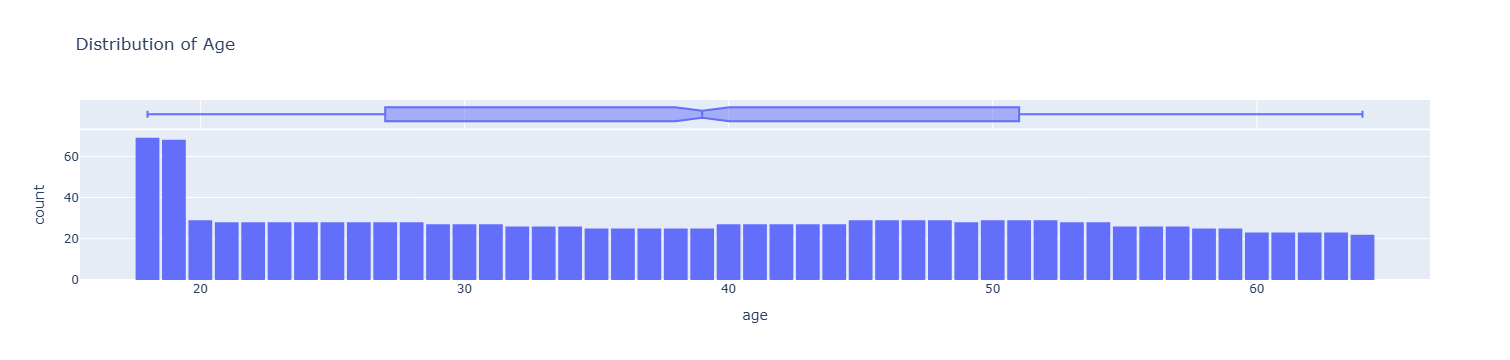

In [57]:
fig = px.histogram(medical_df,
    x='age',
    marginal='box',
    nbins = 47,
    title= 'Distribution of Age')
fig.update_layout(bargap=0.1)
fig.show()


In [15]:
fig = px.histogram(medical_df,
                   x ='bmi',
                   marginal= 'box',
                   color_discrete_sequence=['red'],
                   title='Distribution of BMI (Body Mass Index)')
fig.update_layout(bargap=0.1)
fig.show()

In [16]:
fig = px.histogram(medical_df,
                   x='charges',
                   marginal='box',#marginal adds an additional small plot beside the main histogram. (rug,violin,box)
                   color='smoker',#Divide the histogram into groups based on the smoker column and give each group a different color.
                   color_discrete_sequence=['green','grey'],
                   title='Annual Medical Charges')
#color → How do I separate the groups?
#marginal → What extra distribution plot should I add?
fig.update_layout(bargap=0.1)
fig.show()

In [17]:
fig = px.histogram(medical_df,
                   x='region',
                   marginal='box',
                   color='sex',
                   color_discrete_sequence=['pink','blue'],
                   title='Region with Sex')
fig.update_layout(bargap=0.1)
fig.show()

In [18]:
medical_df.smoker.value_counts()

smoker
no     1064
yes     274
Name: count, dtype: int64

In [19]:
px.histogram(medical_df,x='smoker',color='sex',title='Smoker')

In [20]:
fig = px.scatter(medical_df,
                 x='age',
                 y='charges',
                 color='smoker',
                 opacity=0.8,
                 hover_data=['sex'],
                 title='Age vs charges'
                )
fig.update_traces(marker_size=5)
fig.show()

In [21]:
#BMI VS Charges

fig = px.scatter(medical_df, 
                 x='bmi', 
                 y='charges', 
                 color='smoker', 
                 opacity=0.8,
                 
                 hover_data=['sex'], 
                 title='BMI vs. Charges')
fig.update_yaxes(dtick=10000)
fig.update_traces(marker_size=5)
fig.show()

In [22]:
px.violin(medical_df, #violin : as a combination of a box plot + distribution shape.
          x='children',
          y='charges',
          title='Children vs charges')
# For each number of children, show the distribution of medical charges.
# Violin shape → distribution of charges for that number of children

# Wider part → many observations have charges around that value
# Narrower part → fewer observations
# Long shape → values are spread over a larger range
# Short shape → values are concentrated in a smaller range

In [23]:
px.violin(medical_df, #violin : as a combination of a box plot + distribution shape.
          x='region',
          y='charges',
          title='Children vs charges')

# Now we check that which data is how much give correlation value (0,1) this is range , so when we have more than we assume more depends on each other

In [24]:
medical_df.charges.corr(medical_df.age)

np.float64(0.29900819333064765)

In [25]:
medical_df.charges.corr(medical_df.bmi)
 

np.float64(0.19834096883362892)

In [26]:
medical_df.charges.corr(medical_df.children)

np.float64(0.06799822684790487)

In [27]:
smoker_values = {'yes':1,'no':0}
smoker_numeric = medical_df.smoker.map(smoker_values)
medical_df.charges.corr(smoker_numeric)

np.float64(0.7872514304984772)

In [28]:
medical_df.corr(numeric_only=True) # numeric_only=true is neccessary without this i get this erro "could not convert string to float: 'female'"

,age,bmi,children,charges
age,1.000000,0.109272,0.042469,0.299008
bmi,0.109272,1.000000,0.012759,0.198341
children,0.042469,0.012759,1.000000,0.067998
charges,0.299008,0.198341,0.067998,1.000000


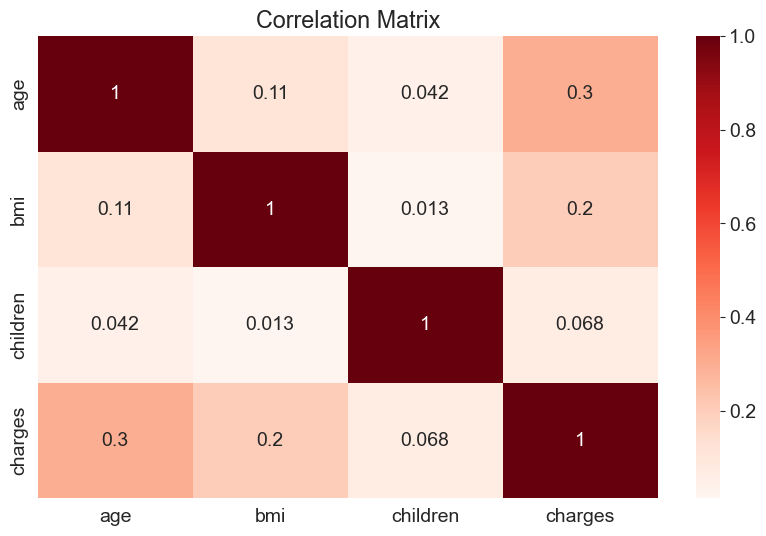

In [29]:
sns.heatmap(medical_df.corr(numeric_only=True),cmap='Reds',annot=True)
plt.title('Correlation Matrix');

In [30]:
non_smoker_df= medical_df[medical_df.smoker=='no']

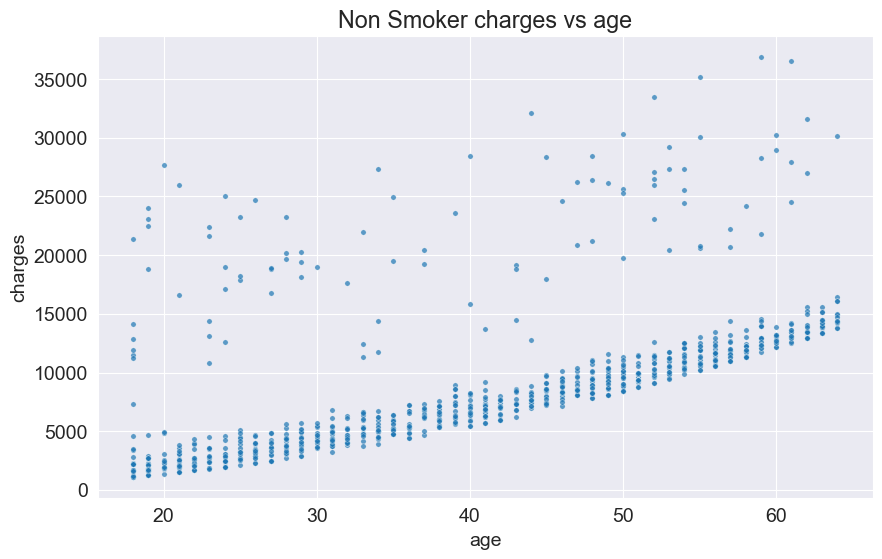

In [31]:
plt.title("Non Smoker charges vs age")
sns.scatterplot(non_smoker_df,x='age',y='charges',alpha=0.7 ,s=15);
# alpha controls how transparent/opaque each dot is
# s controls the size of each scatter point.

Apart from a few exceptions, the points seem to form a line. We'll try and "fit" a line using this points, and use the line to predict charges for a given age. A line on the X&Y coordinates has the following formula:
y=wx+b
The line is characterized two numbers: w (called "slope") and b (called "intercept").
# charges=w×age+b

We'll try determine 
w and 
b for the line that best fits the data.

This technique is called linear regression, and we call the above equation a linear regression model, because it models the relationship between "age" and "charges" as a straight line.

The numbers 
w and 
b are called the parameters or weights of the model.

The values in the "age" column of the dataset are called the inputs to the model and the values in the charges column are called "targets".

Let define a helper function estimate_charges, to compute 
charges, given 
age, 
w and 
b.

In [32]:
def estimate_charges(age,w,b):
    return w*age +b

In [33]:
w=50
b=100
ages = non_smoker_df.age
estimated_charges = estimate_charges(ages,w,b)
estimated_charges

1       1000
2       1500
3       1750
4       1700
5       1650
        ... 
1332    2700
1333    2600
1334    1000
1335    1000
1336    1150
Name: age, Length: 1064, dtype: int64

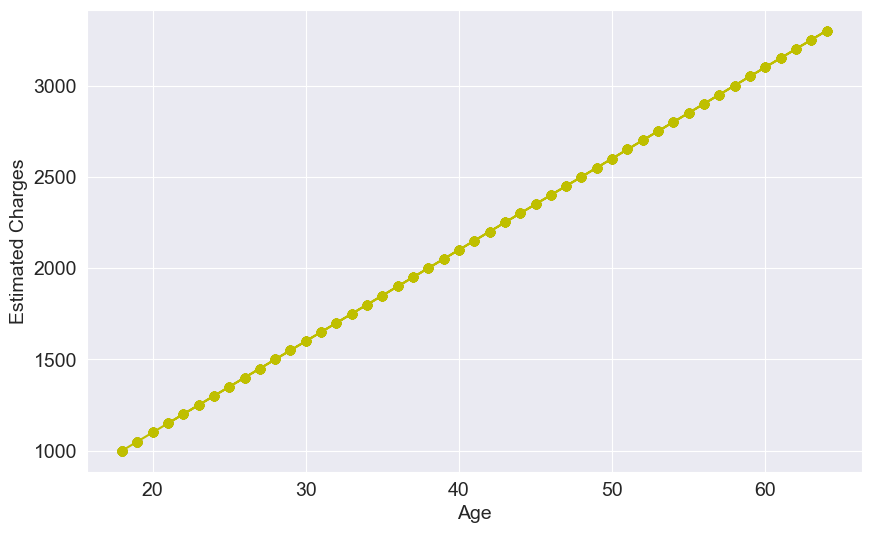

In [34]:
plt.plot(ages ,estimated_charges ,'y-o')
plt.xlabel('Age');
plt.ylabel('Estimated Charges');

We can overlay this line on the actual data, so see how well our model fits the data.
As expected, the points lie on a straight line.

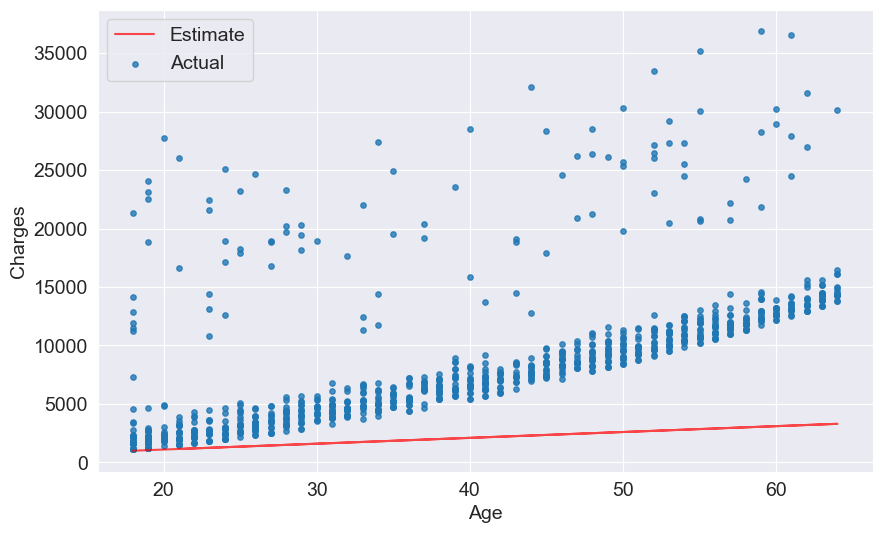

In [58]:
target = non_smoker_df.charges


plt.plot(ages,estimated_charges,'r',alpha= 0.7)
plt.scatter(ages,target,s=15,alpha=0.8)
plt.xlabel('Age')
plt.ylabel('Charges')
plt.legend(['Estimate', 'Actual'])

The our estimates are quite poor and the line does not "fit" the data
, we can try different values of 
w and 
b 

In [36]:
def try_parameter(w,b):
    ages=non_smoker_df.age
    target = non_smoker_df.charges

    estimated_charges = estimate_charges(ages,w,b)
    plt.plot(ages,estimated_charges,'r',alpha=0.8)
    plt.scatter(ages,target,s=8,alpha=0.8)
    plt.xlabel('ages')
    plt.ylabel('charges')
    plt.legend(['Estimated','Actual']);

50 100


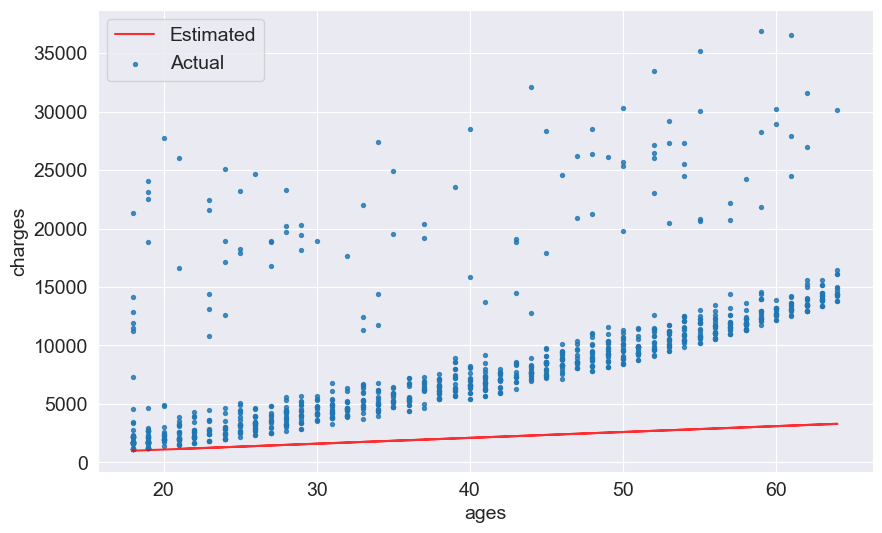

In [37]:
try_parameter(w,b)
print(w,b)

Try various values of 
w and 
b to find a line that best fits the data

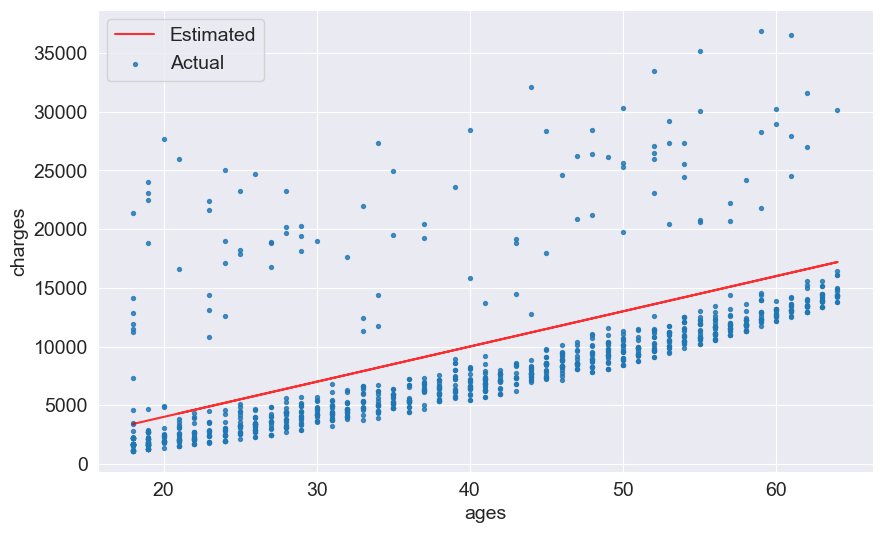

In [38]:
try_parameter(300,-2000)

We need a way to measure numerically how well the line fits the points
Once the "measure of fit" has been computed, we need a way to modify w and b to improve the the fit.
## Loss/Cost Function
We can compare our model's predictions with the actual targets using the following method:
## Root Mean Squared Error (RMSE).
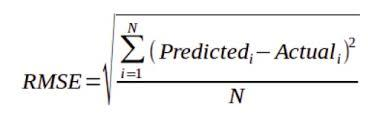!
Calculate the difference between the targets and predictions (the differenced is called the "residual") -->
 Square all elements of the difference matrix to remove negative values.
Calculate the average of the elements in the resulting matrix.
Take the square root of the result

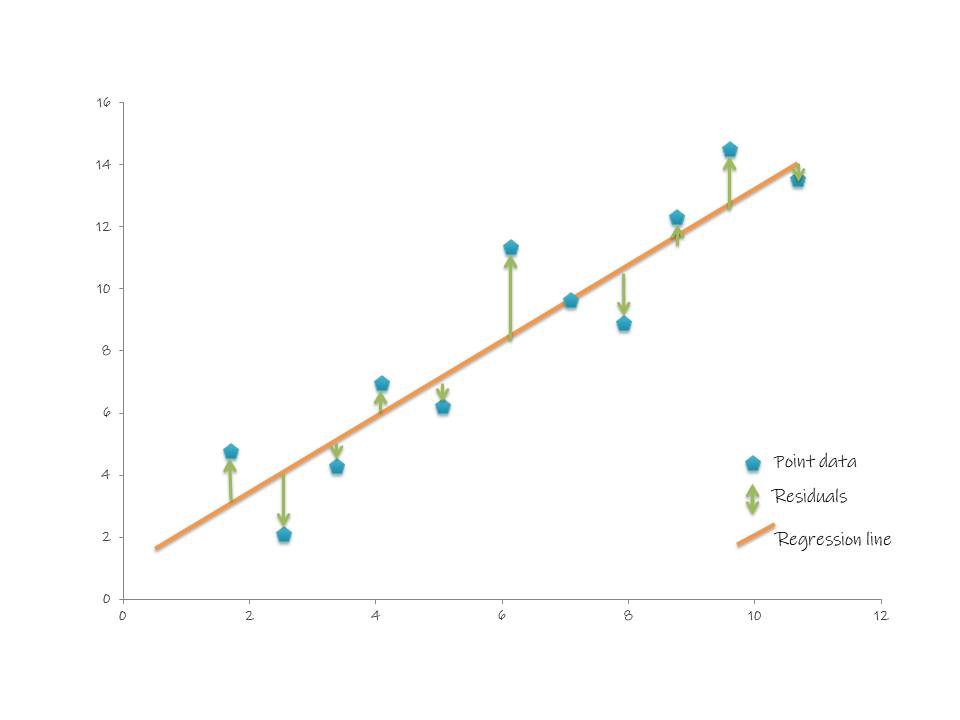

In [39]:
!pip install numpy --quiet #Run quietly — show little or no output/messages in the terminal.

ERROR: Invalid requirement: '#Run': Expected package name at the start of dependency specifier
    #Run
    ^


In [40]:
import numpy as np

def rmse(target,predictions):
    return np.sqrt(np.mean(np.square(target-predictions)))

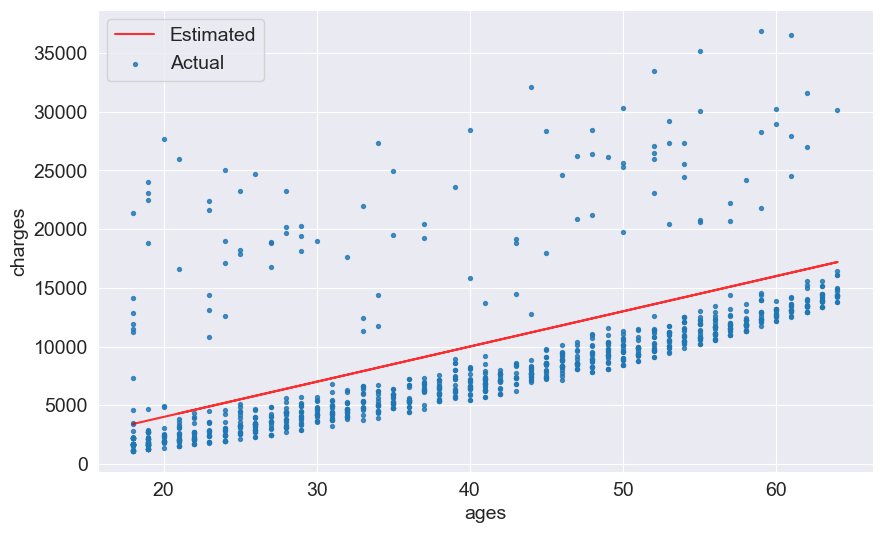

In [41]:
try_parameter(300,-2000)

In [42]:
targets = non_smoker_df['charges'] #.charges
predicted = estimate_charges(non_smoker_df.age,300,-2000)
rmse(targets,predicted)

np.float64(4884.627957453161)

In [43]:
def try_parameters(w, b):
    ages = non_smoker_df.age
    target = non_smoker_df.charges
    predictions = estimate_charges(ages, w, b)
    
    plt.plot(ages, predictions, 'r', alpha=0.9);
    plt.scatter(ages, target, s=8,alpha=0.8);
    plt.xlabel('Age');
    plt.ylabel('Charges')
    plt.legend(['Prediction', 'Actual']);
    
    loss = rmse(target, predictions)
    print("RMSE Loss: ", loss)

RMSE Loss:  4690.343699969419


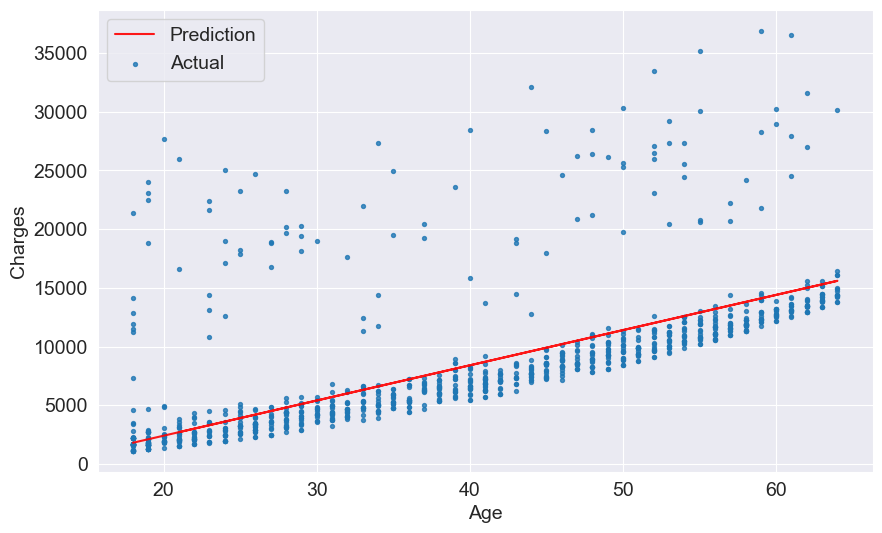

In [44]:
try_parameters(300,-3600)

different values of 
w and 
b to minimize the RMSE loss.
    lowest value of loss i am able to achieve is # 4690

Now i need a optimizer that automatically find best fit line ,
we have two type :
1. Ordinary least SQUARES: (better for smaller dataset) -using matrix operations
2. Stochastic gradient descent:(better for larger dataset) -uses a iterative approach
### objective: to minimize the loss


In [45]:
!pip install scikit-learn --quiet

In [46]:
from sklearn.linear_model import LinearRegression

In [47]:
model = LinearRegression()
help(model.fit)

Help on method fit in module sklearn.linear_model._base:

fit(X, y, sample_weight=None) method of sklearn.linear_model._base.LinearRegression instance
    Fit linear model.

    Parameters
    ----------
    X : {array-like, sparse matrix} of shape (n_samples, n_features)
        Training data.

    y : array-like of shape (n_samples,) or (n_samples, n_targets)
        Target values. Will be cast to X's dtype if necessary.

    sample_weight : array-like of shape (n_samples,), default=None
        Individual weights for each sample.

        .. versionadded:: 0.17
           parameter *sample_weight* support to LinearRegression.

    Returns
    -------
    self : object
        Fitted Estimator.



Not that the input X must be a 2-d array, so we'll need to pass a dataframe, instead of a single column.

In [48]:
inputs = non_smoker_df[['age']] # 2D array require in input model for training
targets = non_smoker_df.charges
print('input.shape : ',inputs.shape)
print('target.shape: ',targets.shape)

input.shape :  (1064, 1)
target.shape:  (1064,)


In [49]:
model.fit(inputs,targets)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [50]:
model.predict(np.array([[23],[37],[61]]))

C:\Users\jhaku\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning:

X does not have valid feature names, but LinearRegression was fitted with feature names



array([ 4055.30443855,  7796.78921819, 14210.76312614])

In [51]:
predictions = model.predict(inputs)
# print('INPUT : ',inputs)
# print('TARGET : ',targets)
predictions

array([2719.0598744 , 5391.54900271, 6727.79356686, ..., 2719.0598744 ,
       2719.0598744 , 3520.80661289], shape=(1064,))

In [52]:
rmse(targets,predictions)

np.float64(4662.505766636395)

In [53]:
print(model.coef_) # w
print(model.intercept_) # b

[267.24891283]
-2091.4205565650846


are these parameters close to your best guesses?

RMSE Loss:  4662.505766636395


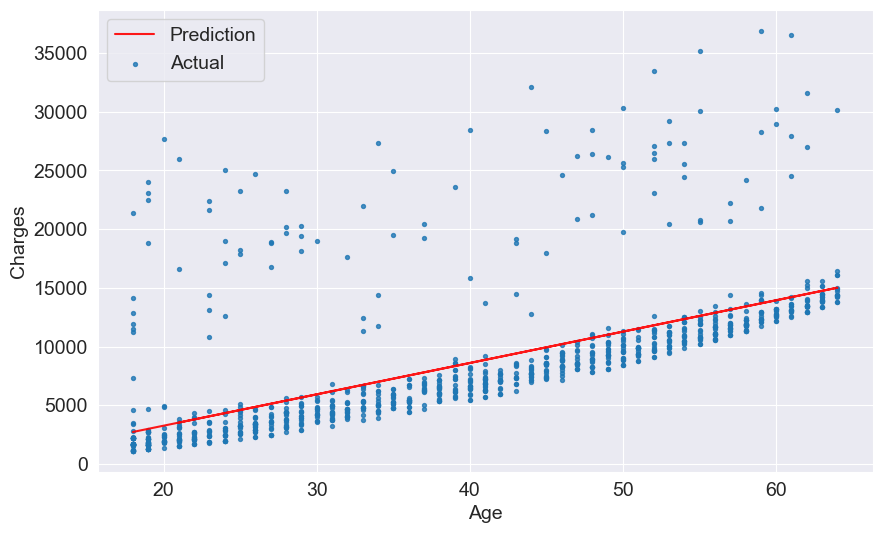

In [54]:
try_parameters(model.coef_,model.intercept_)

### Repeat the steps is this section to train a linear regression model to estimate medical charges for smokers.

In [59]:
smoker_df= medical_df[medical_df.smoker=='yes']

In [62]:
smoker_df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.90,0,yes,southwest,16884.9240
11,62,female,26.29,0,yes,southeast,27808.7251
14,27,male,42.13,0,yes,southeast,39611.7577
19,30,male,35.30,0,yes,southwest,36837.4670
23,34,female,31.92,1,yes,northeast,37701.8768


<Axes: xlabel='age', ylabel='charges'>

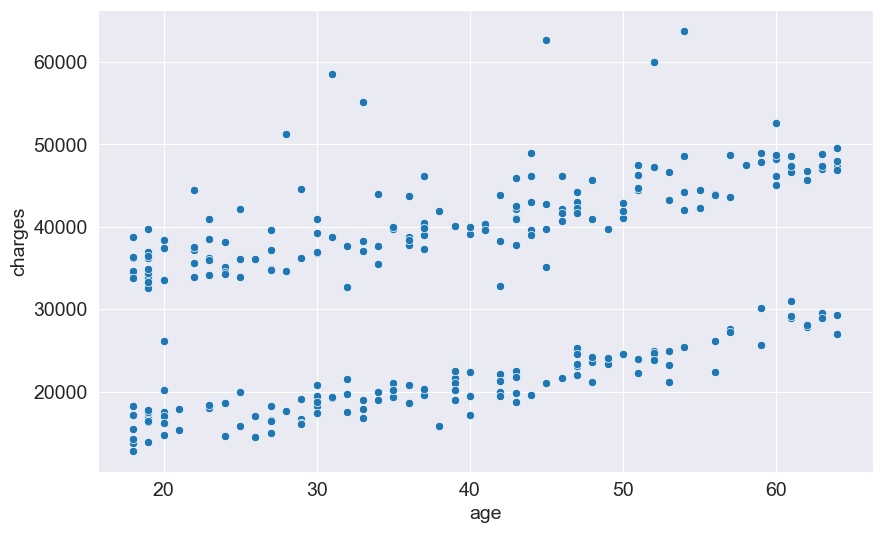

In [73]:
sns.scatterplot(smoker_df,x="age",y="charges")

In [74]:
smoker_df.age.corr(smoker_df.charges)

np.float64(0.36822444373077773)

In [85]:
input_smoker = smoker_df[["age"]]
target_smoker = smoker_df["charges"]


In [88]:
prediction_smoker = model.predict(input_smoker) # this i check from non_smoker data what i get 
rmse(target_smoker,prediction_smoker) # calculate loss by that model

np.float64(26148.867808867617)

In [89]:
new_model = LinearRegression()


In [90]:
new_model.fit(input_smoker,target_smoker)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [95]:
smoker_prediction_ = new_model.predict(input_smoker)# this is new model for smoker only . in this we check prediction
rmse(target_smoker,smoker_prediction_) # here i calculate loss through this 

np.float64(10711.00334810241)

In [98]:
def try_parameters_smoker(w, b):# new try_parameter_smoker
    ages =  smoker_df.age
    target =  smoker_df.charges
    predictions = estimate_charges(ages, w, b)
    
    plt.plot(ages, predictions, 'r', alpha=0.9);
    plt.scatter(ages, target, s=8,alpha=0.8);
    plt.xlabel('Age');
    plt.ylabel('Charges')
    plt.legend(['Prediction', 'Actual']);
    
    loss = rmse(target, predictions)
    print("RMSE Loss: ", loss)

RMSE Loss:  10711.00334810241


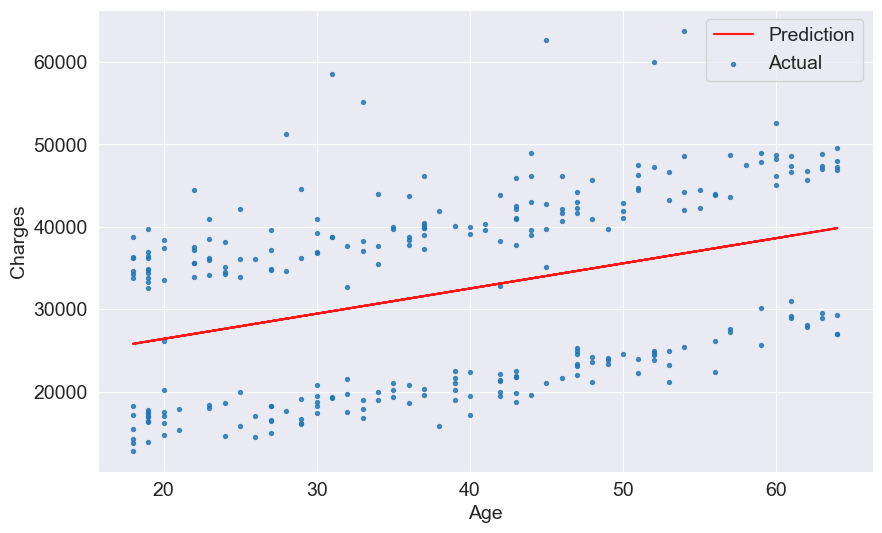

In [99]:
try_parameters_smoker(new_model.coef_,new_model.intercept_)

In [103]:
print(new_model.coef_, new_model.intercept_)

[305.23760211] 20294.12812691597


###Congratulations, you've just trained your first machine learning model! Machine learning is simply the process of computing the best parameters to model the relationship between some feature and targets.

Every machine learning problem has three components:

* Model
* Cost Function
* Optimizer

In [111]:
# it takes just a few lines of code to train a machine learning model using scikit-learn.


#Create inputs and targets
inputs, targets = non_smoker_df[["age"]],non_smoker_df["charges"]

#Create and train model
model = LinearRegression().fit(inputs,targets)

#Generate predictions
predictions = model.predict(inputs)

#Compute loss to evalute the model
loss = rmse(targets,predictions)
print("LOSS",loss)

LOSS 4662.505766636395


In [108]:
smoker_inputs ,smoker_targets = smoker_df[["age"]],smoker_df["charges"]

new_model = LinearRegression().fit(smoker_inputs,smoker_targets)

smoker_predictions = new_model.predict(smoker_inputs)

loss = rmse(smoker_targets, smoker_predictions)
print("LOSS",loss)

LOSS 10711.00334810241


## Linear Regression using Multiple Features

So far, we've used on the "age" feature to estimate "charges". Adding another feature like "bmi" is fairly straightforward. We simply assume the following relationship:

$charges = w_1 \times age + w_2 \times bmi + b$

We need to change just one line of code to include the BMI.

#Now study only through non_smoker_df bcz get less loss

In [114]:
inputs

,age,bmi
1,18,33.770
2,28,33.000
3,33,22.705
4,32,28.880
5,31,25.740
...,...,...
1332,52,44.700
1333,50,30.970
1334,18,31.920
1335,18,36.850


In [113]:
inputs , targets = non_smoker_df[["age","bmi"]] , non_smoker_df["charges"]

# Here we observe only input we have multiple column , we already give 2D array as input in model 

#Create and train model
model = LinearRegression().fit(inputs,targets)

#Generate predictions
predictions = model.predict(inputs)

#Compute loss to evalute the model
loss = rmse(targets,predictions)
print("LOSS",loss)

LOSS 4662.3128354612945


In [115]:
non_smoker_df.charges.corr(non_smoker_df.bmi)

np.float64(0.08403654312833272)

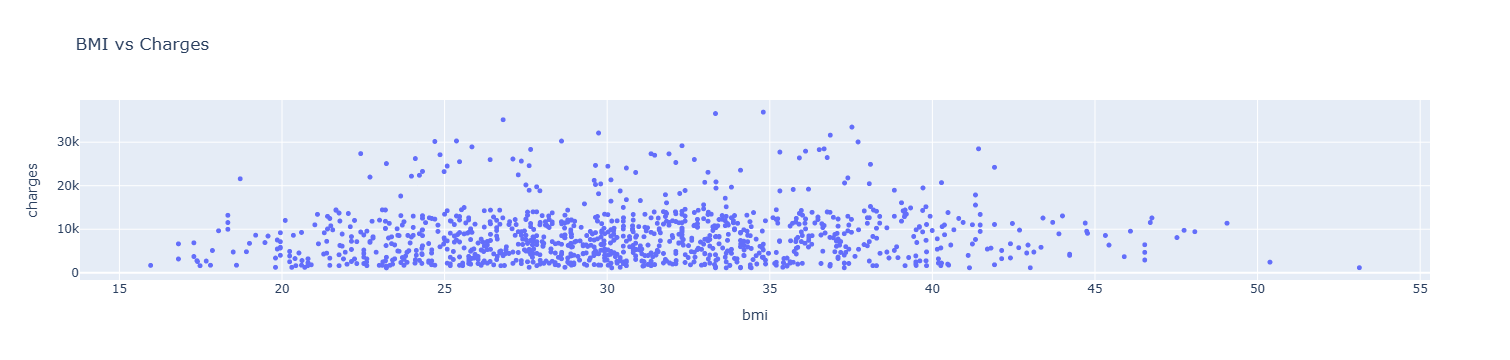

In [120]:
fig = px.scatter(non_smoker_df,x="bmi",y = "charges",title="BMI vs Charges")
fig.update_traces(marker_size=5)
fig.show()

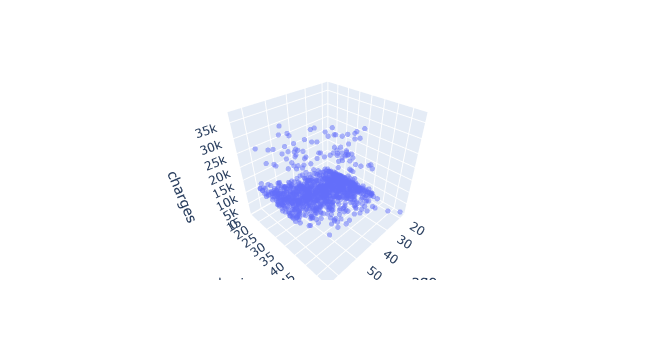

In [121]:
fig = px.scatter_3d(non_smoker_df, x='age', y='bmi', z='charges')
fig.update_traces(marker_size=3, marker_opacity=0.5)
fig.show()

In [122]:
model.coef_, model.intercept_

(array([266.87657817,   7.07547666]), np.float64(-2293.632090648869))

Let's go one step further, and add the final numeric column: "children", which seems to have some correlation with "charges".

$charges = w_1 \times age + w_2 \times bmi + w_3 \times charges + b$

In [125]:
# Create inputs and targets
inputs, targets = non_smoker_df[['age', 'bmi', 'children']], non_smoker_df['charges']

# Create and train the model
model = LinearRegression().fit(inputs, targets)

# Generate predictions
predictions = model.predict(inputs)

# Compute loss to evalute the model
loss = rmse(targets, predictions)
print('Loss:', loss)

Loss: 4608.470405038246


In [127]:
# Create inputs and targets
inputs, targets = smoker_df[['age', 'bmi', 'children']], smoker_df['charges']

# Create and train the model
model = LinearRegression().fit(inputs, targets)

# Generate predictions
predictions = model.predict(inputs)

# Compute loss to evalute the model
loss = rmse(targets, predictions)
print('Loss:', loss)

Loss: 5718.202480524155


In [128]:
smoker_df.bmi.corr(smoker_df.charges)

np.float64(0.8064806070155405)

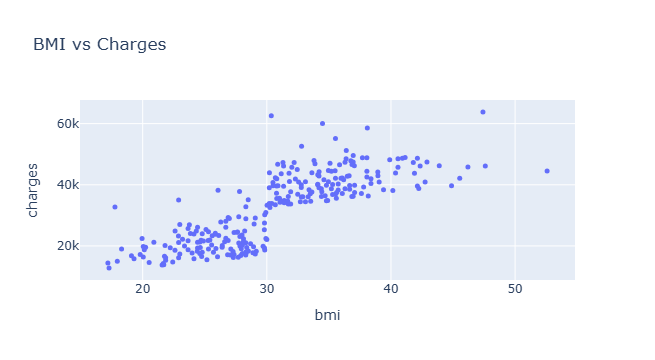

In [130]:
fig = px.scatter(smoker_df,x="bmi",y= "charges",title="BMI vs Charges")
fig.update_traces(marker_size=5)
fig.show()

In [132]:
# Let check  both together smoker and non_smoker 
#  medical_df 

# Create inputs and targets
inputs, targets = medical_df[['age', 'bmi', 'children']], medical_df['charges']

# Create and train the model
model = LinearRegression().fit(inputs, targets)

# Generate predictions
predictions = model.predict(inputs)

# Compute loss to evalute the model
loss = rmse(targets, predictions)
print('Loss:', loss)

Loss: 11355.317901125973


## Using Categorical Features for Machine Learning

So far we've been using only numeric columns, since we can only perform computations with numbers. If we could use categorical columns like "smoker", we can train a single model for the entire dataset.

To use the categorical columns, we simply need to convert them to numbers. There are three common techniques for doing this:

1. If a categorical column has just two categories (it's called a binary category), then we can replace their values with 0 and 1.
2. If a categorical column has more than 2 categories, we can perform one-hot encoding i.e. create a new column for each category with 1s and 0s.
3. If the categories have a natural order (e.g. cold, neutral, warm, hot), then they can be converted to numbers (e.g. 1, 2, 3, 4) preserving the order. These are called ordinals



In [139]:
#Let do binary Categorical  replace
# first check smoker data


# sns.barplot(data=medical_df,x= "smoker",y="charges" )

smoker_codes = {"yes":1,"no":0}
medical_df["smoker_codes"] = medical_df.smoker.map(smoker_codes)
medical_df

,age,sex,bmi,children,smoker,region,charges,smoker_codes
0,19,female,27.900,0,yes,southwest,16884.92400,1
1,18,male,33.770,1,no,southeast,1725.55230,0
2,28,male,33.000,3,no,southeast,4449.46200,0
3,33,male,22.705,0,no,northwest,21984.47061,0
4,32,male,28.880,0,no,northwest,3866.85520,0
...,...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830,0
1334,18,female,31.920,0,no,northeast,2205.98080,0
1335,18,female,36.850,0,no,southeast,1629.83350,0
1336,21,female,25.800,0,no,southwest,2007.94500,0


In [141]:
medical_df.charges.corr(medical_df.smoker_codes)

np.float64(0.7872514304984772)

We can now use the `smoker_df` column for linear regression.

$charges = w_1 \times age + w_2 \times bmi + w_3 \times charges + w_4 \times smoker + b$

In [143]:
# Create inputs and targets
inputs, targets = medical_df[['age', 'bmi', 'children', 'smoker_codes']], medical_df['charges']

# Create and train the model
model = LinearRegression().fit(inputs, targets)

# Generate predictions
predictions = model.predict(inputs)

# Compute loss to evalute the model
loss = rmse(targets, predictions)
print('Loss:', loss)

Loss: 6056.439217188081


### Here after doing binary categorical replace we 
#get loss reduce 11355 to 6056 almost 50% this i svery good , So here
We understand never ignore categorical data

In [ ]:
# We can also doing this with Sex male and female by 1 nd 0 encoding , but i understand concept here


### One-hot Encoding

The "region" column contains 4 values, so we'll need to use hot encoding and create a new column for each region.

![](https://i.imgur.com/n8GuiOO.png)

<Axes: xlabel='region', ylabel='charges'>

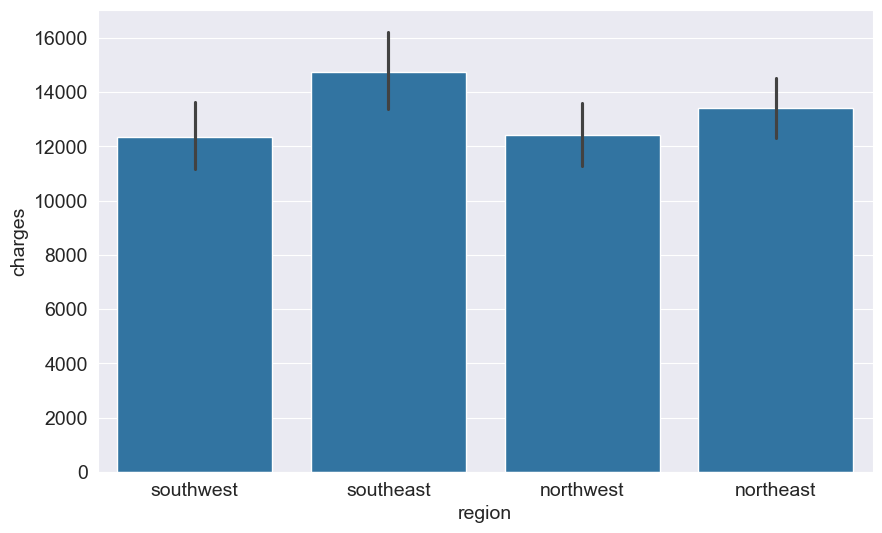

In [148]:
sns.barplot(data = medical_df,x="region",y = "charges")

In [151]:
from sklearn import preprocessing
enc = preprocessing.OneHotEncoder() #This creates a OneHotEncoder object.
enc.fit(medical_df[["region"]]) #The fit() method learns the unique categories present in the region column.
# Important: fit() learns the categories but does not transform your data yet.

enc.categories_ #This displays the categories learned by the encoder.



[array(['northeast', 'northwest', 'southeast', 'southwest'], dtype=object)]

In [153]:
one_hot = enc.transform(medical_df[["region"]]).toarray() #The transform() method converts each region into a binary vector.
one_hot

array([[0., 0., 0., 1.],
       [0., 0., 1., 0.],
       [0., 0., 1., 0.],
       ...,
       [0., 0., 1., 0.],
       [0., 0., 0., 1.],
       [0., 1., 0., 0.]], shape=(1338, 4))

In [154]:
medical_df[['northeast', 'northwest', 'southeast', 'southwest']] = one_hot
medical_df

,age,sex,bmi,children,smoker,region,charges,smoker_codes,northeast,northwest,southeast,southwest
0,19,female,27.900,0,yes,southwest,16884.92400,1,0.0,0.0,0.0,1.0
1,18,male,33.770,1,no,southeast,1725.55230,0,0.0,0.0,1.0,0.0
2,28,male,33.000,3,no,southeast,4449.46200,0,0.0,0.0,1.0,0.0
3,33,male,22.705,0,no,northwest,21984.47061,0,0.0,1.0,0.0,0.0
4,32,male,28.880,0,no,northwest,3866.85520,0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830,0,0.0,1.0,0.0,0.0
1334,18,female,31.920,0,no,northeast,2205.98080,0,1.0,0.0,0.0,0.0
1335,18,female,36.850,0,no,southeast,1629.83350,0,0.0,0.0,1.0,0.0
1336,21,female,25.800,0,no,southwest,2007.94500,0,0.0,0.0,0.0,1.0


In [157]:
# Create inputs and targets
input_cols = ['age', 'bmi', 'children', 'smoker_codes',  'northeast', 'northwest', 'southeast', 'southwest']
inputs, targets = medical_df[input_cols], medical_df['charges']

# Create and train the model
model = LinearRegression().fit(inputs, targets)

# Generate predictions
predictions = model.predict(inputs)

# Compute loss to evalute the model
loss = rmse(targets, predictions)
print('Loss:', loss)

Loss: 6042.033215394104


In [158]:
weights_df = pd.DataFrame({
    'feature': np.append(input_cols, 1),
    'weight': np.append(model.coef_, model.intercept_)
})
weights_df

,feature,weight
0,age,256.973582
1,bmi,338.664638
2,children,474.566470
3,smoker_codes,23836.300502
4,northeast,586.479228
5,northwest,234.297116
6,southeast,-447.880899
7,southwest,-372.895445
8,1,-12576.749108


While it seems like BMI and the "northeast" have a higher weight than age, keep in mind that the range of values for BMI is limited (15 to 40) and the "northeast" column only takes the values 0 and 1.

Because different columns have different ranges, we run into two issues:

1. We can't compare the weights of different column to identify which features are important
2. A column with a larger range of inputs may disproportionately affect the loss and dominate the optimization process.

For this reason, it's common practice to scale (or standardize) the values in numeric column by subtracting the mean and dividing by the standard deviation.

![](https://i.imgur.com/dT5fLFI.png)

We can apply scaling using the StandardScaler class from `scikit-learn`.

In [159]:
from sklearn.preprocessing import StandardScaler

In [160]:
numeric_cols = ['age', 'bmi', 'children'] 
scaler = StandardScaler()
scaler.fit(medical_df[numeric_cols])

,copy,True
,with_mean,True
,with_std,True


In [161]:
print(scaler.mean_,scaler.var_)

[39.20702541 30.66339686  1.09491779] [197.25385199  37.16008997   1.45212664]


In [162]:
scaled_inputs = scaler.transform(medical_df[numeric_cols])
scaled_inputs

array([[-1.43876426, -0.45332   , -0.90861367],
       [-1.50996545,  0.5096211 , -0.07876719],
       [-0.79795355,  0.38330685,  1.58092576],
       ...,
       [-1.50996545,  1.0148781 , -0.90861367],
       [-1.29636188, -0.79781341, -0.90861367],
       [ 1.55168573, -0.26138796, -0.90861367]], shape=(1338, 3))

In [166]:
cat_cols = ['smoker_codes',  'northeast', 'northwest', 'southeast', 'southwest']
categorical_data = medical_df[cat_cols].values
categorical_data

array([[1., 0., 0., 0., 1.],
       [0., 0., 0., 1., 0.],
       [0., 0., 0., 1., 0.],
       ...,
       [0., 0., 0., 1., 0.],
       [0., 0., 0., 0., 1.],
       [1., 0., 1., 0., 0.]], shape=(1338, 5))

In [167]:
inputs = np.concatenate((scaled_inputs, categorical_data), axis=1)
targets = medical_df.charges

# Create and train the model
model = LinearRegression().fit(inputs, targets)

# Generate predictions
predictions = model.predict(inputs)

# Compute loss to evalute the model
loss = rmse(targets, predictions)
print('Loss:', loss)

Loss: 6042.033215394104


We can now compare the weights in the formula:

$charges = w_1 \times age + w_2 \times bmi + w_3 \times charges + w_4 \times smoker + w_5 \times sex + w_6 \times region + b$

In [168]:
weights_df = pd.DataFrame({
    'feature': np.append(numeric_cols + cat_cols, 1),
    'weight': np.append(model.coef_, model.intercept_)
})
weights_df.sort_values('weight', ascending=False)

,feature,weight
3,smoker_codes,23836.300502
8,1,8402.640125
0,age,3609.119197
1,bmi,2064.468352
4,northeast,586.479228
2,children,571.872609
5,northwest,234.297116
7,southwest,-372.895445
6,southeast,-447.880899


#### From here We study how to divide sample data into test set and training set

In [169]:
from sklearn.model_selection import train_test_split

In [170]:
inputs_train, inputs_test, targets_train, targets_test = train_test_split(inputs, targets, test_size=0.1)

In [171]:
# Create and train the model
model = LinearRegression().fit(inputs_train, targets_train)

# Generate predictions
predictions_test = model.predict(inputs_test)

# Compute loss to evalute the model
loss = rmse(targets_test, predictions_test)
print('Test Loss:', loss)

Test Loss: 6369.164343988797


In [172]:
# Generate predictions
predictions_train = model.predict(inputs_train)

# Compute loss to evalute the model
loss = rmse(targets_train, predictions_train)
print('Training Loss:', loss)

Training Loss: 6007.810149668747


## How to Approach a Machine Learning Problem
Here's a strategy you can apply to approach any machine learning problem:

1. Explore the data and find correlations between inputs and targets
2. Pick the right model, loss functions and optimizer for the problem at hand
3. Scale numeric variables and one-hot encode categorical data
4. Set aside a test set (using a fraction of the training set)
5. Train the model
6. Make predictions on the test set and compute the loss

In [ ]:
# Next practice dataSet , I could use is house prices like 